# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
from aitlas.datasets import FloodAreaDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose

## Visualize images and masks

Total number of patches: 290


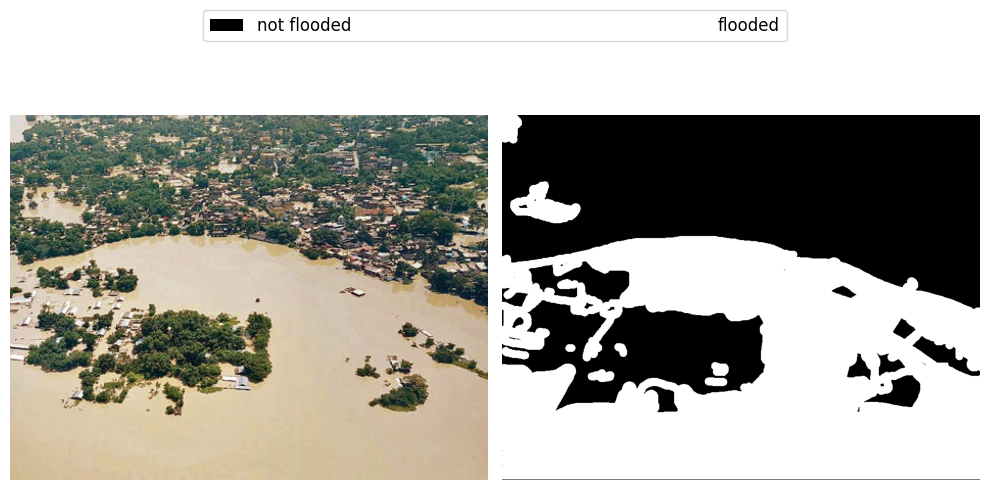

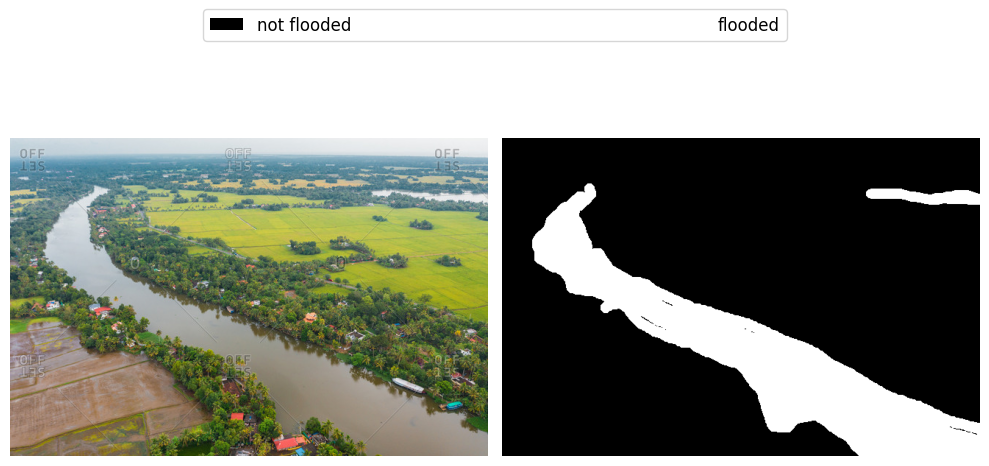

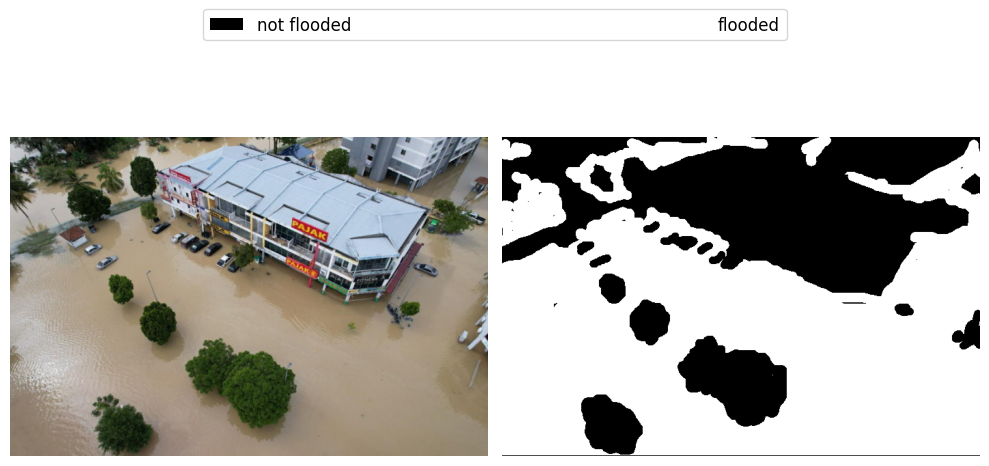

In [ ]:
dataset_config = {
    "data_dir": "./data/flood_area"
}
dataset = FloodAreaDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(100);
dataset.show_image(200);

In [12]:
dataset.data_distribution_table()

,Number of pixels
not flooded,217929112.0
flooded,180325742.0


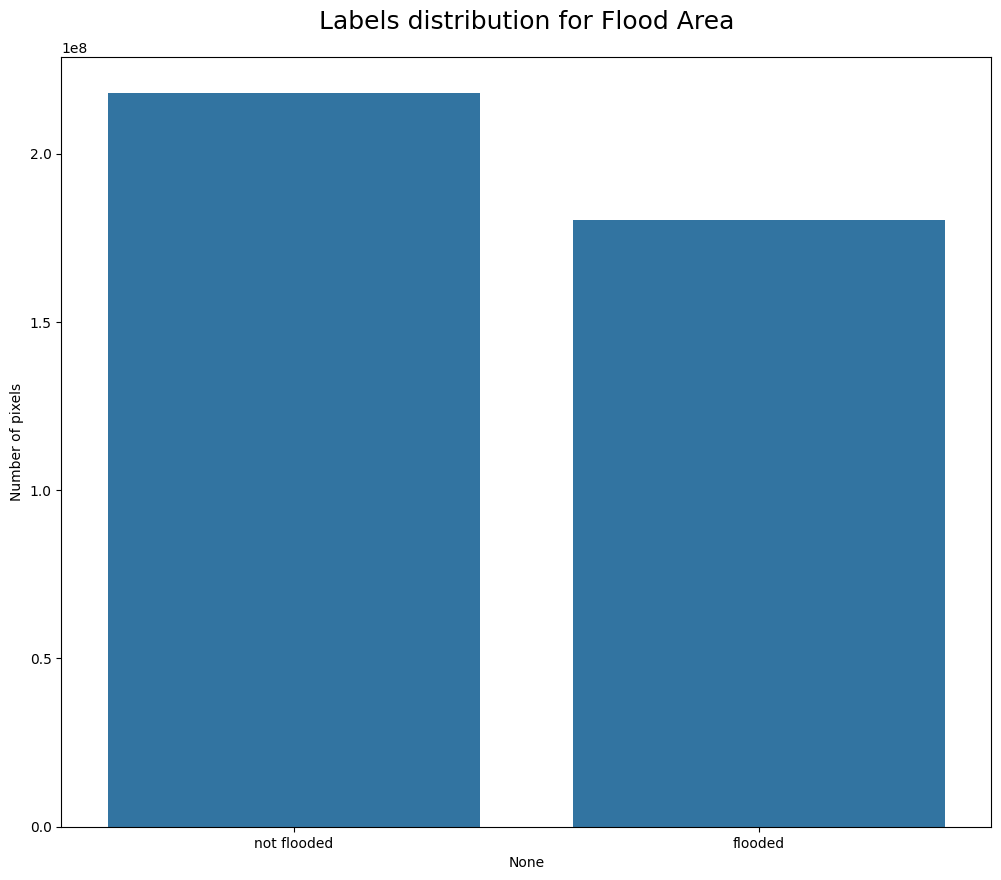

In [13]:
dataset.data_distribution_barchart();

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 10,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/flood_area",
    "csv_file": "./data/flood_area/train.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = FloodAreaDataset(train_dataset_config)
len(train_dataset)

230

## Create the model

In [ ]:
epochs = 10
model_directory = "./data/flood_area"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [66]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-03-26 09:26:22,667 INFO Starting training.
training: 100%|██████████| 23/23 [04:06<00:00, 10.71s/it]
2025-03-26 09:30:29,118 INFO epoch: 1, time: 247, loss:  0.38001
testing on train set: 100%|██████████| 23/23 [04:39<00:00, 12.17s/it]
2025-03-26 09:35:10,409 INFO IOU:0.6990657802509099, IOU mean:0.692725531983496, IOU per Class:[0.76535252 0.62009854]
training: 100%|██████████| 23/23 [03:55<00:00, 10.23s/it]
2025-03-26 09:39:05,671 INFO epoch: 2, time: 235, loss:  0.26227
testing on train set: 100%|██████████| 23/23 [04:01<00:00, 10.50s/it]
2025-03-26 09:43:07,280 INFO IOU:0.7722969621098982, IOU mean:0.7633109204389206, IOU per Class:[0.8357586  0.69086325]
training: 100%|██████████| 23/23 [03:53<00:00, 10.17s/it]
2025-03-26 09:47:01,275 INFO epoch: 3, time: 234, loss:  0.22347
testing on train set: 100%|██████████| 23/23 [04:35<00:00, 11.96s/it]
2025-03-26 09:51:36,366 INFO IOU:0.8003449956581941, IOU mean:0.7909346309153964, IOU per Class:[0.8536876  0.72818166]
training: 100%

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/flood_area",
    "csv_file": "./data/flood_area/val.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = FloodAreaDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/flood_area/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

29


2025-03-26 11:02:07,018 INFO Loading checkpoint /home/dragik/data/FAIR_EO/flood_area/checkpoint.pth.tar
2025-03-26 11:02:07,345 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/flood_area/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 8/8 [01:16<00:00,  9.62s/it]


[{'IOU': 0.8273163553991622,
  'IOU mean': 0.8247743262102745,
  'IOU per Class': array([0.85406382, 0.79548483])}]

## Predictions

2025-03-26 11:03:24,362 INFO Loading checkpoint /home/dragik/data/FAIR_EO/flood_area/checkpoint.pth.tar
2025-03-26 11:03:24,629 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/flood_area/checkpoint.pth.tar at epoch 11


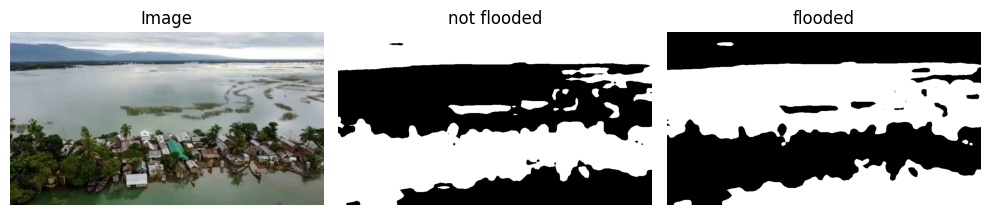

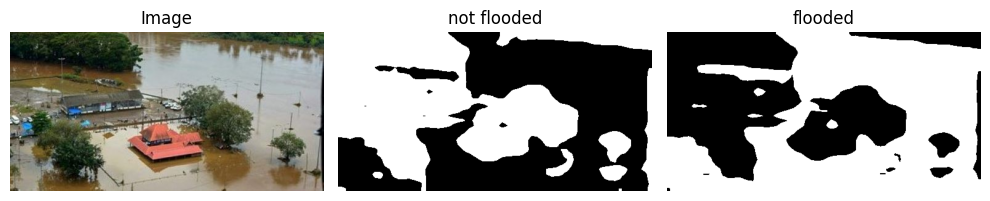

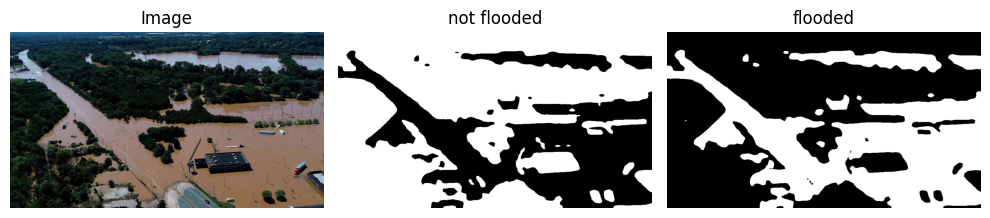

In [ ]:
model_path = "./data/flood_area/checkpoint.pth.tar"
labels = ["not flooded","flooded"]
transform = MinMaxNormTranspose()
model.load_model(model_path)
csv_file = "./data/flood_area/test.csv"

test_list = []
with open(csv_file, mode ='r')as file:
    csvFile = csv.reader(file)
    for lines in csvFile:
        test_list.append(lines[0])

image = image_loader('./data/flood_area/' + test_list[0])
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/flood_area/' + test_list[1])
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/flood_area/' + test_list[10])
fig = model.predict_masks(image, labels, transform)